# HDD Dataset Exploration

The original clone supplies six per-model `*_last_10_day_all_q_raw.csv` datasets. These are already-derived Backblaze 2019 tables, not the original daily archive. The five source supervised models are listed separately from HGST, which is present in the source dataset and included in the SMART availability/correlation trace.

## Paths and Imports

In [1]:
from pathlib import Path
import gc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_DIR = Path.cwd()
while not (PROJECT_DIR / "data" / "raw").is_dir():
    if PROJECT_DIR == PROJECT_DIR.parent:
        raise FileNotFoundError("Could not locate project data/raw directory")
    PROJECT_DIR = PROJECT_DIR.parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
SOURCE_DATASET_DIR = PROJECT_DIR / "source" / "dataset"
PLOT_DIR = PROJECT_DIR / "results" / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
CORE_SMART = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw", "smart_198_raw"]


## Original Dataset Files

In [2]:
dataset_paths = sorted(RAW_DIR.glob("*_last_10_day_all_q_raw.csv"))
if not dataset_paths:
    raise FileNotFoundError(f"No original all-quarter raw datasets found in {RAW_DIR}")
model_names = [p.name.removesuffix("_last_10_day_all_q_raw.csv") for p in dataset_paths]
source_inventory = pd.DataFrame([
    {"file": p.name, "format": p.suffix.lower(), "bytes": p.stat().st_size,
     "present_in_source_clone": (SOURCE_DATASET_DIR / p.name).is_file()}
    for p in dataset_paths
])
source_other_files = pd.DataFrame([
    {"file": p.name, "format": p.suffix.lower(), "bytes": p.stat().st_size}
    for p in sorted(SOURCE_DATASET_DIR.iterdir()) if p.is_file() and p.suffix.lower() in {".txt", ".xlsx", ".sql", ".pdf"}
])
display(source_inventory)
display(source_other_files)


,file,format,bytes,present_in_source_clone
0,HGST HMS5C4040BLE640_last_10_day_all_q_raw.csv,.csv,20273892,True
1,ST12000NM0007_last_10_day_all_q_raw.csv,.csv,70804572,True
2,ST4000DM000_last_10_day_all_q_raw.csv,.csv,42801594,True
3,ST8000DM002_last_10_day_all_q_raw.csv,.csv,19286907,True
4,ST8000NM0055_last_10_day_all_q_raw.csv,.csv,28786820,True
5,TOSHIBA MQ01ABF050_last_10_day_all_q_raw.csv,.csv,689020,True


,file,format,bytes
0,SMART_IDs.txt,.txt,9428
1,SMART_IDs.xlsx,.xlsx,13815


## Dataset Schema

In [3]:
schema_rows = []
for path in dataset_paths:
    sample = pd.read_csv(path, nrows=1000, low_memory=False)
    header = pd.read_csv(path, nrows=0).columns.tolist()
    schema_rows.extend({"model": path.name.removesuffix("_last_10_day_all_q_raw.csv"),
                        "column": column, "dtype": str(sample[column].dtype)}
                       for column in header)
    if path == dataset_paths[0]:
        print(path.name, "sample rows:")
        display(sample.head())
        sample.info()
    del sample
    gc.collect()
schema_table = pd.DataFrame(schema_rows)
display(schema_table)


HGST HMS5C4040BLE640_last_10_day_all_q_raw.csv sample rows:


,date,serial_number,model,capacity_bytes,failure,smart_1_raw,smart_2_raw,smart_3_raw,smart_4_raw,smart_5_raw,...,smart_8_raw,smart_9_raw,smart_10_raw,smart_12_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_196_raw,smart_197_raw,smart_199_raw
0,2019-12-22,PL1331LAGBZ1SH,HGST HMS5C4040BLE640,4000787030016,0,0.0,107.0,544.0,6.0,0.0,...,42.0,16894.0,0.0,6.0,303.0,303.0,23.0,0.0,0.0,0.0
1,2019-12-23,PL1331LAGBZ1SH,HGST HMS5C4040BLE640,4000787030016,0,0.0,107.0,544.0,6.0,0.0,...,42.0,16909.0,0.0,6.0,303.0,303.0,23.0,0.0,0.0,0.0
2,2019-12-24,PL1331LAGBZ1SH,HGST HMS5C4040BLE640,4000787030016,0,0.0,107.0,544.0,6.0,0.0,...,42.0,16941.0,0.0,6.0,303.0,303.0,23.0,0.0,0.0,0.0
3,2019-12-25,PL1331LAGBZ1SH,HGST HMS5C4040BLE640,4000787030016,0,0.0,107.0,544.0,6.0,0.0,...,42.0,16973.0,0.0,6.0,303.0,303.0,23.0,0.0,0.0,0.0
4,2019-12-26,PL1331LAGBZ1SH,HGST HMS5C4040BLE640,4000787030016,0,0.0,107.0,544.0,6.0,0.0,...,42.0,16989.0,0.0,6.0,303.0,303.0,23.0,0.0,0.0,0.0


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            1000 non-null   str    
 1   serial_number   1000 non-null   str    
 2   model           1000 non-null   str    
 3   capacity_bytes  1000 non-null   int64  
 4   failure         1000 non-null   int64  
 5   smart_1_raw     1000 non-null   float64
 6   smart_2_raw     1000 non-null   float64
 7   smart_3_raw     1000 non-null   float64
 8   smart_4_raw     1000 non-null   float64
 9   smart_5_raw     1000 non-null   float64
 10  smart_7_raw     1000 non-null   float64
 11  smart_8_raw     1000 non-null   float64
 12  smart_9_raw     1000 non-null   float64
 13  smart_10_raw    1000 non-null   float64
 14  smart_12_raw    1000 non-null   float64
 15  smart_192_raw   1000 non-null   float64
 16  smart_193_raw   1000 non-null   float64
 17  smart_194_raw   1000 non-null   float64
 18  

,model,column,dtype
0,HGST HMS5C4040BLE640,date,str
1,HGST HMS5C4040BLE640,serial_number,str
2,HGST HMS5C4040BLE640,model,str
3,HGST HMS5C4040BLE640,capacity_bytes,int64
4,HGST HMS5C4040BLE640,failure,int64
...,...,...,...
137,TOSHIBA MQ01ABF050,smart_196_raw,float64
138,TOSHIBA MQ01ABF050,smart_197_raw,float64
139,TOSHIBA MQ01ABF050,smart_199_raw,float64
140,TOSHIBA MQ01ABF050,smart_222_raw,float64


## Dimensions and Failure Labels

In [4]:
overview_rows = []
class_rows = []
for path in dataset_paths:
    frame = pd.read_csv(path, usecols=["date", "failure"], low_memory=False)
    model_name = path.name.removesuffix("_last_10_day_all_q_raw.csv")
    overview_rows.append({"model": model_name, "rows": len(frame),
                          "columns": len(pd.read_csv(path, nrows=0).columns),
                          "date_start": frame["date"].min(), "date_end": frame["date"].max()})
    counts = frame["failure"].value_counts().reindex([0, 1], fill_value=0)
    class_rows.append({"model": model_name, "healthy_rows": int(counts[0]),
                       "failure_rows": int(counts[1]),
                       "failure_pct": 100 * counts[1] / len(frame)})
    del frame
    gc.collect()
dataset_overview = pd.DataFrame(overview_rows)
class_distribution = pd.DataFrame(class_rows)
display(dataset_overview)
display(class_distribution)


,model,rows,columns,date_start,date_end
0,HGST HMS5C4040BLE640,144513,21,2019-01-01,2019-12-31
1,ST12000NM0007,382305,24,2019-01-01,2019-12-31
2,ST4000DM000,233596,26,2019-01-01,2019-12-31
3,ST8000DM002,99325,26,2019-01-01,2019-12-31
4,ST8000NM0055,146709,26,2019-01-01,2019-12-31
5,TOSHIBA MQ01ABF050,5335,19,2019-01-01,2019-12-31


,model,healthy_rows,failure_rows,failure_pct
0,HGST HMS5C4040BLE640,143951,562,0.388892
1,ST12000NM0007,371048,11257,2.944508
2,ST4000DM000,229629,3967,1.698231
3,ST8000DM002,98132,1193,1.201107
4,ST8000NM0055,144530,2179,1.485253
5,TOSHIBA MQ01ABF050,4559,776,14.545455


## SMART Attribute Availability

In [5]:
availability_rows = []
for model_name in model_names:
    path = RAW_DIR / f"{model_name}_last_10_day_all_q_raw.csv"
    columns = pd.read_csv(path, nrows=0).columns.tolist()
    smart_columns = [c for c in columns if c.startswith("smart_") and c.endswith("_raw")]
    for attribute in CORE_SMART:
        availability_rows.append({"model": model_name, "attribute": attribute,
                                  "available": attribute in smart_columns})
    print(f"{model_name}: {len(smart_columns)} raw SMART attributes")
    print(smart_columns)
smart_availability = pd.DataFrame(availability_rows)
display(smart_availability.pivot(index="model", columns="attribute", values="available"))


HGST HMS5C4040BLE640: 16 raw SMART attributes
['smart_1_raw', 'smart_2_raw', 'smart_3_raw', 'smart_4_raw', 'smart_5_raw', 'smart_7_raw', 'smart_8_raw', 'smart_9_raw', 'smart_10_raw', 'smart_12_raw', 'smart_192_raw', 'smart_193_raw', 'smart_194_raw', 'smart_196_raw', 'smart_197_raw', 'smart_199_raw']
ST12000NM0007: 19 raw SMART attributes
['smart_1_raw', 'smart_4_raw', 'smart_5_raw', 'smart_7_raw', 'smart_9_raw', 'smart_12_raw', 'smart_187_raw', 'smart_188_raw', 'smart_190_raw', 'smart_192_raw', 'smart_193_raw', 'smart_194_raw', 'smart_195_raw', 'smart_197_raw', 'smart_198_raw', 'smart_199_raw', 'smart_240_raw', 'smart_241_raw', 'smart_242_raw']
ST4000DM000: 21 raw SMART attributes
['smart_1_raw', 'smart_4_raw', 'smart_5_raw', 'smart_7_raw', 'smart_9_raw', 'smart_12_raw', 'smart_183_raw', 'smart_184_raw', 'smart_187_raw', 'smart_188_raw', 'smart_189_raw', 'smart_190_raw', 'smart_192_raw', 'smart_193_raw', 'smart_194_raw', 'smart_197_raw', 'smart_198_raw', 'smart_199_raw', 'smart_240_raw

attribute,smart_187_raw,smart_188_raw,smart_197_raw,smart_198_raw,smart_5_raw
model,,,,,
HGST HMS5C4040BLE640,False,False,True,False,True
ST12000NM0007,True,True,True,True,True
ST4000DM000,True,True,True,True,True
ST8000DM002,True,True,True,True,True
ST8000NM0055,True,True,True,True,True
TOSHIBA MQ01ABF050,False,False,True,False,True


## Missing Values

In [6]:
missing_rows = []
for path in dataset_paths:
    frame = pd.read_csv(path, low_memory=False)
    model_name = path.name.removesuffix("_last_10_day_all_q_raw.csv")
    missing_rows.extend({"model": model_name, "column": column,
                         "missing_values": int(count),
                         "missing_pct": 100 * count / len(frame)}
                        for column, count in frame.isna().sum().items())
    del frame
    gc.collect()
missing_table = pd.DataFrame(missing_rows)
display(missing_table[missing_table["missing_values"] > 0])
print("Columns with missing values:", int((missing_table["missing_values"] > 0).sum()))
print("Row-level missing-value entries:", int(missing_table["missing_values"].sum()))


,model,column,missing_values,missing_pct


Columns with missing values: 0
Row-level missing-value entries: 0


## SMART Statistical Summary

In [7]:
summary_rows = []
for model_name in model_names:
    path = RAW_DIR / f"{model_name}_last_10_day_all_q_raw.csv"
    available = [c for c in CORE_SMART if c in pd.read_csv(path, nrows=0).columns]
    frame = pd.read_csv(path, usecols=available, low_memory=False)
    for attribute in available:
        values = frame[attribute]
        summary_rows.append({"model": model_name, "attribute": attribute,
                             "count": int(values.count()), "mean": values.mean(),
                             "std": values.std(), "median": values.median(),
                             "p99": values.quantile(0.99), "nonzero_pct": 100 * values.ne(0).mean()})
    del frame
    gc.collect()
smart_summary = pd.DataFrame(summary_rows)
display(smart_summary)


,model,attribute,count,mean,std,median,p99,nonzero_pct
0,HGST HMS5C4040BLE640,smart_5_raw,144513,8.262509e-01,2.524794e+01,0.0,0.000000e+00,0.541820
1,HGST HMS5C4040BLE640,smart_197_raw,144513,5.607800e-02,2.569658e+00,0.0,0.000000e+00,0.243577
2,ST12000NM0007,smart_5_raw,382305,1.456522e+02,1.846798e+03,0.0,2.608000e+03,5.400400
3,ST12000NM0007,smart_187_raw,382305,6.590903e+00,5.561641e+02,0.0,3.000000e+00,1.929350
4,ST12000NM0007,smart_188_raw,382305,2.420164e+08,4.867967e+09,0.0,4.295033e+09,1.740234
5,ST12000NM0007,smart_197_raw,382305,7.891919e-01,6.015190e+01,0.0,0.000000e+00,0.887250
6,ST12000NM0007,smart_198_raw,382305,7.891919e-01,6.015190e+01,0.0,0.000000e+00,0.887250
7,ST4000DM000,smart_5_raw,233596,1.329099e+01,6.342629e+02,0.0,0.000000e+00,0.912259
8,ST4000DM000,smart_187_raw,233596,2.849235e-01,2.140176e+00,0.0,8.000000e+00,4.391342
9,ST4000DM000,smart_188_raw,233596,9.231751e-02,1.370459e+00,0.0,2.000000e+00,3.372061


## Record Counts and Failure Rates

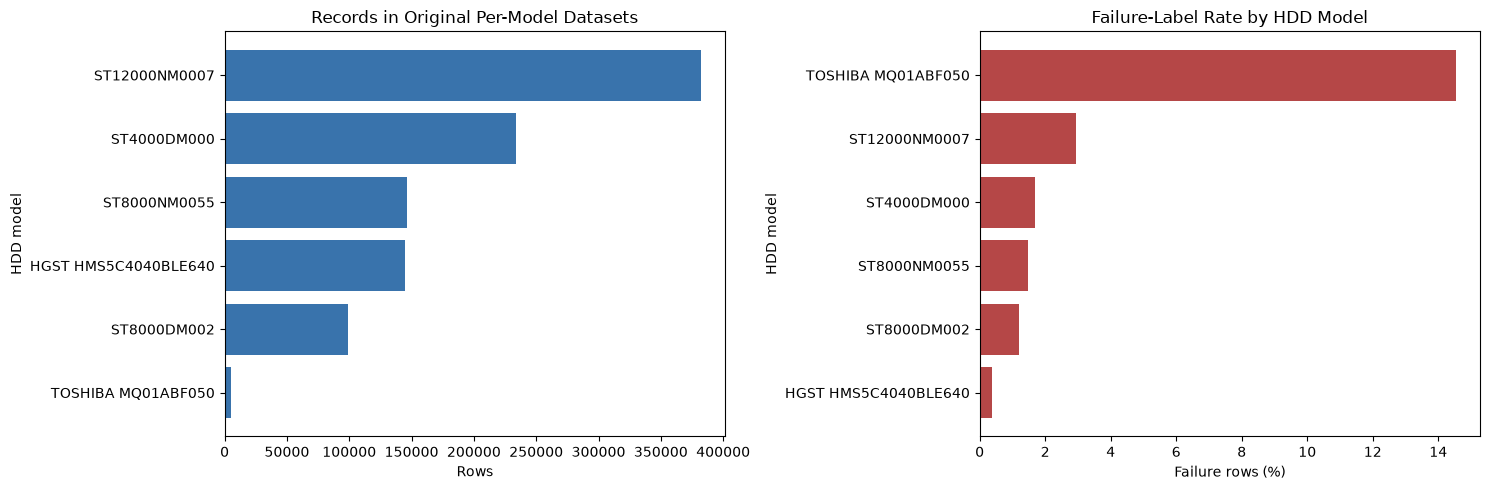

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
count_plot = dataset_overview.sort_values("rows")
axes[0].barh(count_plot["model"], count_plot["rows"], color="#3973ac")
axes[0].set(title="Records in Original Per-Model Datasets", xlabel="Rows", ylabel="HDD model")
rate_plot = class_distribution.sort_values("failure_pct")
axes[1].barh(rate_plot["model"], rate_plot["failure_pct"], color="#b54747")
axes[1].set(title="Failure-Label Rate by HDD Model", xlabel="Failure rows (%)", ylabel="HDD model")
fig.tight_layout()
fig.savefig(PLOT_DIR / "exploration_model_counts_and_failure_rate.png", dpi=160, bbox_inches="tight")
plt.show()


## Core SMART Availability

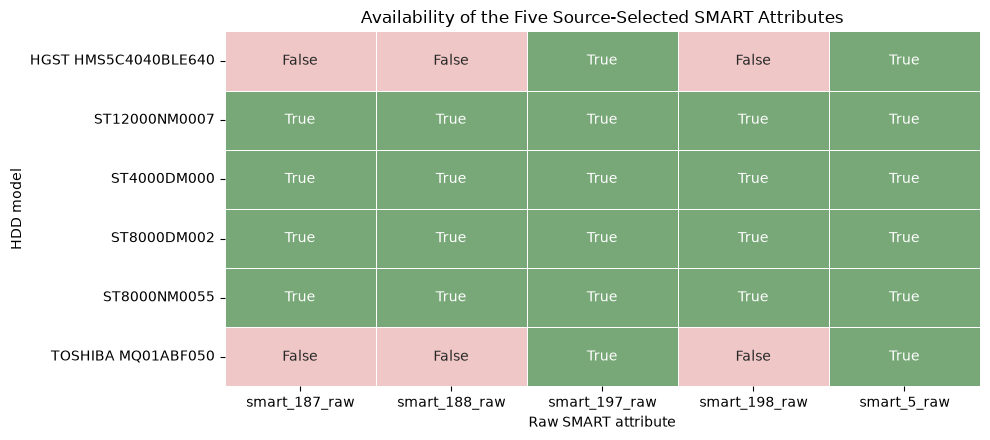

In [9]:
availability_matrix = smart_availability.pivot(index="model", columns="attribute", values="available")
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(availability_matrix.astype(int), annot=availability_matrix,
            fmt="", cmap=sns.color_palette(["#f0c7c7", "#78a878"], as_cmap=True),
            cbar=False, linewidths=0.5, ax=ax)
ax.set(title="Availability of the Five Source-Selected SMART Attributes",
       xlabel="Raw SMART attribute", ylabel="HDD model")
fig.tight_layout()
fig.savefig(PLOT_DIR / "exploration_core_smart_availability.png", dpi=160, bbox_inches="tight")
plt.show()


## Nonzero Rates by Label

In [10]:
nonzero_rows = []
for model_name in model_names:
    path = RAW_DIR / f"{model_name}_last_10_day_all_q_raw.csv"
    available = [c for c in CORE_SMART if c in pd.read_csv(path, nrows=0).columns]
    frame = pd.read_csv(path, usecols=["failure", *available], low_memory=False)
    for attribute in available:
        rates = frame.assign(nonzero=frame[attribute].ne(0)).groupby("failure")["nonzero"].mean()
        for label, rate in rates.items():
            nonzero_rows.append({"model": model_name, "failure": int(label),
                                 "attribute": attribute, "nonzero_pct": 100 * rate})
    del frame
    gc.collect()
nonzero_rates = pd.DataFrame(nonzero_rows)
display(nonzero_rates)


,model,failure,attribute,nonzero_pct
0,HGST HMS5C4040BLE640,0,smart_5_raw,0.472383
1,HGST HMS5C4040BLE640,1,smart_5_raw,18.327402
2,HGST HMS5C4040BLE640,0,smart_197_raw,0.202847
3,HGST HMS5C4040BLE640,1,smart_197_raw,10.676157
4,ST12000NM0007,0,smart_5_raw,3.821069
5,ST12000NM0007,1,smart_5_raw,57.457582
6,ST12000NM0007,0,smart_187_raw,1.008225
7,ST12000NM0007,1,smart_187_raw,32.291019
8,ST12000NM0007,0,smart_188_raw,1.511125
9,ST12000NM0007,1,smart_188_raw,9.291996


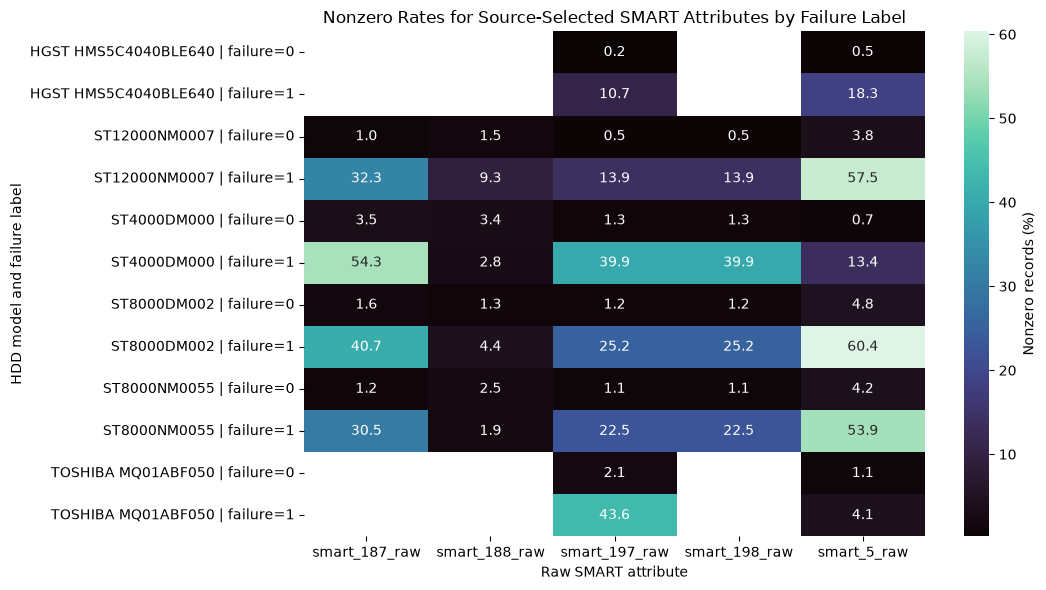

In [11]:
nonzero_plot = nonzero_rates.copy()
nonzero_plot["model_label"] = nonzero_plot["model"] + " | failure=" + nonzero_plot["failure"].astype(str)
rate_matrix = nonzero_plot.pivot(index="model_label", columns="attribute", values="nonzero_pct")
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(rate_matrix, annot=True, fmt=".1f", cmap="mako", cbar_kws={"label": "Nonzero records (%)"}, ax=ax)
ax.set(title="Nonzero Rates for Source-Selected SMART Attributes by Failure Label",
       xlabel="Raw SMART attribute", ylabel="HDD model and failure label")
fig.tight_layout()
fig.savefig(PLOT_DIR / "exploration_core_smart_nonzero_by_label.png", dpi=160, bbox_inches="tight")
plt.show()
